# Figure 2 Simulated training data set improves random forest multiclass classification performance

Andrew E. Davidson   
aedavids@ucsc.edu  
Date: 2026-10-06.  
Copyright (c) 2027, Regents of the University of California All rights reserved.  
https://polyformproject.org/licenses/noncommercial/1.0.0  

## <span style="color:red;background-color:yellow;">uses models trained in multiClassifiers.ipynb and deepMultiClassifiers.ipynb notebooks</span>

Confusion matrix reproduced from Chen et al. under the terms of the Creative Commons Attribution License for the human RNA-only, 500-feature multiclass classifier (average sensitivity, 52.5%). Chen et al. reported an average sensitivity of 60.4% when microbial RNA features were included, although the corresponding confusion matrix was not published. 

In [1]:
defaultNotebookName="manuscriptSimulationImprovesPerformance"

from cliUtilities import configLogging
import logging

# rootLogger = configLogging(logLevel="INFO")
rootLogger = configLogging(logLevel="WARN")
logger = logging.getLogger(__name__)

2026-11-21 10:35:55,735 WARNING cliUtilities.py configLogging() line:61] [BEGIN]
2026-11-21 10:35:55,735 WARNING cliUtilities.py configLogging() line:67] [PYTHONPATH : /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks]
2026-11-21 10:35:55,736 WARNING cliUtilities.py configLogging() line:68] [FILE: /private/home/aedavids/graceM/src/python/cliUtilities.py]
2026-11-21 10:35:55,737 WARNING cliUtilities.py configLogging() line:69] [PWD: /private/home/aedavids/graceM/src/jupyterNotebooks]


In [2]:
from copy import deepcopy 
import joblib
from itertools import cycle
import math
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import PercentFormatter

from matplotlib.axes import Axes
from matplotlib.figure import Figure

import numpy as np
import os
import pandas as pd
from pathlib import Path

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

from tensorflow import keras
#
# local imports
#
from notebookUtils import appendToPYTHONPATH, getNotebookName


ORIG_PYTHONPATH = os.environ['PYTHONPATH']

extraRNA_PythonPath1 = '/private/home/aedavids/extraCellularRNA' 
extraRNA_PythonPath2 = '/private/home/aedavids/extraCellularRNA/src'
appendToPYTHONPATH([extraRNA_PythonPath1, extraRNA_PythonPath2])

from archive.dataTypes import  ModelConfig, ModelBundle
from archive.archiveUtilities import loadArchive, printDictTree 

from models.configMLWorkflow import configMultiLoad, configTrain # configEvaluate 
from plots.plotROCCurve import calculateMultiClass
from plots.plotPanel import combineFiguresLayout, getSubplotWidthAndHeight, Panel
from plots.plotPanel import displayPDFInNotebook

from utilities import isOrderedCategoricalSeries

I0000 00:00:1795286158.333286 1794476 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795286158.406523 1794476 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795286160.415216 1794476 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-21 10:36:00,798 WARNING notebookUtils.py appendToPYTHONPATH() line:40] [Updated PYTHONPATH: /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks:/private/home/aedavids/extraCellularRNA:/private/home/aedavids/extraCellularRNA/src]
/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `impo

In [3]:
notebookName, notebookDir = getNotebookName(defaultNotebookName)
print(f'notebookName: {notebookName}')
print(f'notebookDir: {notebookDir}')

notebookOutDir = f'{notebookDir}/{notebookName}.out'
print(f'notebookOutDir: {notebookOutDir}')

imgOutDir = f'{notebookOutDir}/img'
os.makedirs(imgOutDir, exist_ok=True)
print(f'imgOutDir: {imgOutDir}')

imgPanelOutDir = f'{imgOutDir}/panel'
os.makedirs(imgPanelOutDir, exist_ok=True)
print(f'imgPanelOutDir: {imgPanelOutDir}')


notebookName: manuscriptSimulationImprovesPerformance
notebookDir: /private/home/aedavids/graceM/src/jupyterNotebooks
notebookOutDir: /private/home/aedavids/graceM/src/jupyterNotebooks/manuscriptSimulationImprovesPerformance.out
imgOutDir: /private/home/aedavids/graceM/src/jupyterNotebooks/manuscriptSimulationImprovesPerformance.out/img
imgPanelOutDir: /private/home/aedavids/graceM/src/jupyterNotebooks/manuscriptSimulationImprovesPerformance.out/img/panel


In [4]:
# _G : global use to insure we do not pick up globals in function by accident 
# durring refactoring

simulatedDataRootDir_G = "/private/groups/kimlab/aedavids/fagazi/simulatedData"
scratchDataRootDir_G = "/scratch/aedavids/fagazi/simulatedData"

realDataRoot_G = "/private/groups/kimlab/data/elife"
realDataPath_G = f'{realDataRoot_G}/elife_all_norm_counts_2023-05-18.csv'
realMetaDataPath_G = f'{realDataRoot_G}/elife_scaled_metaData_2023-05-18.csv'

In [5]:
# path to pretrained models
multiClassifiersRootOutDir_G = f'{notebookDir}/multiClassifier.out'

In [6]:
plotLayout_7Subplots: dict[str, Panel] = {
    # Top row: confusion matrices
    "a": Panel(
        "a", leftMm=0, topMm=0,
        widthMm=60, heightMm=65,
    ),
    "b": Panel(
        "b", leftMm=60, topMm=0,
        widthMm=60, heightMm=65,
    ),
    "c": Panel(
        "c", leftMm=120, topMm=0,
        widthMm=60, heightMm=65,
    ),

    # Middle row: equally sized ROC plots
    "d": Panel(  # Five-cancer ROC
        "d", leftMm=0, topMm=65,
        widthMm=85, heightMm=55,
    ),
    "e": Panel(  # Four-cancer ROC
        "e", leftMm=95, topMm=65,
        widthMm=85, heightMm=55,
    ),

    # Bottom row
    "f": Panel(  # NN architecture table
        "f", leftMm=0, topMm=129,
        widthMm=85, heightMm=47,
    ),
    "g": Panel(  # Five-cancer deep NN confusion matrix
        "g", leftMm=105, topMm=120,
        widthMm=65, heightMm=65,
    ),
}

# plotLayout_G = plotLayout_5Subplots
plotLayout_G = plotLayout_7Subplots

In [7]:
def plotChenConfusionMatrix(
    widthMm=60,
    heightMm=65,
    fontSize=7,
    showPercent=True,
    showColorbar=True,
    ):
    """
    I upload pdf to chatGPT and asked to recreate page 8 figure 5 panel letter A
    
    Recreate Chen et al., eLife 2022, Figure 5A.

    Values are published percentages averaged across bootstrap replicates.
    Rows: true classes. Columns: predicted classes.
    Colors approximate the original; only diagonal cells are colored.

    Returns
    -------
    fig, ax
    """
    labels = [
        "Colorectum",
        "Stomach",
        "Liver",
        "Lung",
        "Esophagus",
    ]

    values = np.array([
        [40.7, 24.6,  0.7, 22.7, 11.3],
        [34.4, 51.8,  0.0,  8.1,  5.7],
        [ 2.8,  2.9, 82.8,  4.9,  6.6],
        [21.8, 24.7,  3.5, 34.8, 15.1],
        [16.2,  8.2,  5.3, 18.1, 52.2],
    ])

    # Approximate the original pink-to-red diagonal shading.
    cmap = LinearSegmentedColormap.from_list(
        "chenDiagonal",
        ["#ff9999", "#cc0000"],
    )
    cmap.set_bad("white")

    # Mask off-diagonal cells so they remain white.
    diagonalValues = np.ma.array(
        values,
        mask=~np.eye(len(labels), dtype=bool),
    )

    fig, ax = plt.subplots(
        figsize=(widthMm / 25.4, heightMm / 25.4),
        layout="constrained",
    )
    
    # title = 'Chen et al. (2022) \nMulticlass (5 cancers) Human cfRNA'
    title = 'Chen et al. (2022) \nMulticlass (5 cancers) human cfRNA'
    ax.set_title( title, fontsize=fontSize)

    image = ax.imshow(
        diagonalValues,
        cmap=cmap,
        norm=Normalize(vmin=20, vmax=85, clip=True),
        interpolation="nearest",
        aspect="equal",
    )

    ax.set_xticks(np.arange(len(labels)), labels=labels)
    ax.set_yticks(np.arange(len(labels)), labels=labels)

    # Original figure places column labels above the matrix.
    ax.tick_params(
        axis="x",
        top=True,
        labeltop=True,
        bottom=False,
        labelbottom=False,
        length=0,
        labelsize=fontSize,
    )
    
    # Chen put the x-axis tick labels on top
    # ax.tick_params(axis="y", length=0, labelsize=fontSize)

    # for text in ax.get_xticklabels():
    #     text.set_rotation(55)
    #     text.set_ha("left")
    #     text.set_rotation_mode("anchor")
    
    # put x-axis tick labels on bottom for consistency
    ax.tick_params(
        axis="x",
        top=False,
        labeltop=False,
        bottom=True,
        labelbottom=True,
        length=0,
        labelsize=fontSize,
    )
    
    ax.tick_params(
            axis="y",
            left=True,
            labelleft=True,
            right=False,
            labelright=False,
            length=0,
            labelsize=fontSize,
        )

    for text in ax.get_xticklabels():
        text.set_rotation(45)
        text.set_ha("right")
        text.set_rotation_mode("anchor")   
    
    ax.set_xlabel("Predicted label", fontsize=fontSize)
    ax.set_ylabel("True label", fontsize=fontSize)

    # Dashed internal boundaries, as in the original.
    for boundary in np.arange(0.5, len(labels) - 0.5, 1):
        ax.axhline(boundary, color="black", linestyle="--", linewidth=0.5)
        ax.axvline(boundary, color="black", linestyle="--", linewidth=0.5)

    for row in range(len(labels)):
        for column in range(len(labels)):
            value = values[row, column]
            label = f"{value:.1f}%" if showPercent else f"{value:.1f}"

            ax.text(
                column,
                row,
                label,
                ha="center",
                va="center",
                fontsize=fontSize,
                color=(
                    "white"
                    if row == column and value >= 50
                    else "black"
                ),
            )

    if showColorbar:
        colorbar = fig.colorbar(
            image,
            ax=ax,
            fraction=0.045,
            pad=0.04,
            ticks=[20, 50, 80],
        )
        colorbar.ax.yaxis.set_major_formatter(
            PercentFormatter(xmax=100, decimals=0)
        )
        colorbar.ax.tick_params(labelsize=fontSize, length=2)

    return fig, ax


layout[a].widthMm : 60
layout[a].heightMm : 65


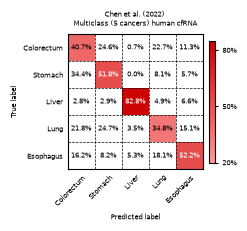

In [8]:
aId = "a"
aWidthMM, aHeightMM = getSubplotWidthAndHeight(plotLayout_G, aId)
chenFig, chenAx = plotChenConfusionMatrix(
                        widthMm=aWidthMM, #+ 15, #10, #40, #=120,
                        heightMm=aHeightMM, #+ 20, #15, #35, #=100,
                        fontSize=5, #6, #7,
                    )
plotLayout_G[aId].figure = chenFig

## <span style="color:red;background-color:yellow;">recreate our 5 cancer RM model</span>
ref : src/jupyterNotebooks/randomForestMultiClassifiers/multiClassifierXAI_manuscript.ipynb

In [9]:
elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom300_1vsAllRelaxed.sh.out_best300_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        
                        # ROC, sensitivity, specificity, confusion plots expect
                        # the positive condition to be labeled 1, and the negative
                        # test results labeled 0.
                        # "Healthy_donor",
                        # make sure categories[0] is the negative diagnostic test class
                        categories = [  "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer", "Lung_Cancer", "Stomach_Cancer" ],
                    )

elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G.abstract = "5 class multi-classfiler data set set used in simulation manscript"

mcRF300ImgOutdir = f'{notebookOutDir}/{elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G.dataSetName}/img'
os.makedirs(mcRF300ImgOutdir, exist_ok=True)
print(f'mcRF300ImgOutdir : {mcRF300ImgOutdir}')

mcRF300ImgOutdir : /private/home/aedavids/graceM/src/jupyterNotebooks/manuscriptSimulationImprovesPerformance.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/img


In [10]:
elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G = ModelConfig(
                        dataSetName = "elifeMultiClassifierFrom400BinaryDropHealthy+Lung",
                        rootOutDir = notebookOutDir,
                        simulatedDataPath = f"{scratchDataRootDir_G}/elifeMultiClassifierFrom400Binary.sh.out_best400_results",
                        realDataPath = realDataPath_G,
                        realMetaDataPath = realMetaDataPath_G,
                        deseqResultsType = 'results',
                        categories = [ "Colorectal_Cancer", "Esophagus_Cancer",  
                                        "Liver_Cancer",  "Stomach_Cancer" ],
                    )

elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G.abstract = "4 class multi-classfiler data set set used in simulation manscript"

mcRF400ImgOutdir = f'{notebookOutDir}/{elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G.dataSetName}/img'
os.makedirs(mcRF400ImgOutdir, exist_ok=True)
print(f'mcRF400ImgOutdir : {mcRF400ImgOutdir}')

mcRF400ImgOutdir : /private/home/aedavids/graceM/src/jupyterNotebooks/manuscriptSimulationImprovesPerformance.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/img


In [11]:
def loadMultiRFArchive(
        config : ModelConfig,
    ):
    ''' 
    loads data and pretrained models
    
    raises error if pre-trained model does not exist
    
    we need to load the data to be able to make predictions need to regenerate
    confusion matrices    
    '''
    dataSetName = config.dataSetName
    print(f'data set : {dataSetName}\n')
    configMultiLoad(config)

    archivePath = f'{multiClassifiersRootOutDir_G}/{dataSetName}/archive.json'
    archiveDict = loadArchive(archivePath) 

    if archiveDict :
        printDictTree(archiveDict)
        print()
        for dbPath in archiveDict['diagnosticBundles']:
            print(dbPath)
            
    # load model if it exists else train
    needtoSave : bool = configTrain(config, archiveDict)

    if needtoSave:
        emsg = f'pre trained model was not found!'
        logger.error(emsg)
        raise FileNotFoundError(emsg)
    
    
# loadMultiRFArchive(
#     config=elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G,
# )


In [12]:
def getModelBundle(
        config : ModelConfig,
        dataSet : str) -> ModelBundle:
    ''' 
    TODO
        validDataSets = ["simTrain", "simVal", "simTest", "real"]
    '''
    validDataSets = ["simTrain", "simVal", "simTest", "real"]
    if not dataSet in validDataSets :
        logger.error(f"invalide dataSet : {dataSet} should be key with value {validDataSets}")
        return
    
    diagnosticBundle = config.dataDict['multi']
    mb =  getattr(diagnosticBundle, dataSet)
    print(f'{dataSet}.shape : {mb.X.shape}') 
    
    return mb



In [13]:
def plotArtworkFinalCM(
        modelBundle : ModelBundle,
        widthInMM : int,
        heightInMM : int,
        chenOrdering : list[str],
        title : str, 
        fontSize : int = 5, #6, #7,
        predictionClassOrder=None,
    ) -> plt.figure:
    ''' 
    TODO
    
    arguments :
    
    predictionClassOrder :
        use with keras (deep neural network) models
        decodes the NN’s output columns into class names. It must match training.
    
    ref : 
        src/python/models/mlWorkflow.py evaluate()
        src/python/plots/plotConfusionMatrix.py plotConfusionMatrix()
        see https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay

    '''
    XDF = modelBundle.X
    model = modelBundle.model
    logger.debug(f'AEDWIP X.shape {XDF.shape}')
    logger.debug(f'AEDWIP model {type(model)}')
    
    
    # predictions = model.predict( XDF )
    if predictionClassOrder is None:
        # Random forest: predict() already returns class labels.
        predictions = model.predict(XDF)
    else:
        # Multiclass neural network with softmax output.
        probabilities = model.predict(XDF, verbose=0)
        classNames = np.asarray(predictionClassOrder)

        if probabilities.ndim != 2:
            raise ValueError("Expected a 2D array of multiclass probabilities.")

        if probabilities.shape[1] != len(classNames):
            raise ValueError("Class names do not match the model's output size.")

        predictions = classNames[probabilities.argmax(axis=1)]
    
    #labelEncoder = modelBundle.labelEncoder

    # ySeries value type is an ordered pd.Categorical 
    ySeries = modelBundle.y
    if not isOrderedCategoricalSeries(ySeries):
        errMsg = f'argument ySeries {type(ySeries)} expected pandas series with an ordered categorical dtype'
        logger.error(errMsg)
        raise TypeError(errMsg)
    
    encodeYSeries = ySeries.cat.codes
    
    # chenOrdering = ['Colorectal_Cancer', 'Stomach_Cancer',
    #                 'Liver_Cancer', 'Lung_Cancer', 
    #                 'Esophagus_Cancer']

    
    
    # cfm = confusion_matrix(ySeries, predictions, labels=ySeries.cat.categories)
    cfm = confusion_matrix(ySeries, predictions, labels=chenOrdering)
    
    # Normalize to percentages (row-wise, so each row sums to 100)
    cfm = cfm.astype('float') / cfm.sum(axis=1)[:, np.newaxis] * 100
    
    # disp = ConfusionMatrixDisplay(confusion_matrix=cfm, 
    #                               display_labels=ySeries.cat.categories
    #                               )
    disp = ConfusionMatrixDisplay(confusion_matrix=cfm, 
                                  display_labels=chenOrdering
                                  )    
    
    fig, ax = plt.subplots(
                figsize=(widthInMM / 25.4, heightInMM / 25.4)
        )
    disp.plot(ax=ax)
    
    ax.set_title(title)
    
    ax = disp.ax_
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    
    # strip _Cancer from tick labels
    ax.set_xticks(
        ax.get_xticks(),
        labels=[
            text.get_text().removesuffix("_Cancer")
            for text in ax.get_xticklabels()
            ],
    )

    ax.set_yticks(
        ax.get_yticks(),
        labels=[
            text.get_text().removesuffix("_Cancer")
            for text in ax.get_yticklabels()
        ],
    )
    
     # Add % signs to each text annotation
    for t in ax.texts:
        #t.set_text(t.get_text() + "%") default matplot lib number format displays 1e+2 instead of 100
        val = float(t.get_text())
        # t.set_text(f"{val:.1f}%")
        # print(f"aEDWIP  displayAsPrecentage {val:.0f} {val:.1f}")
        t.set_text(f"{val:.0f}%")
        
    # set the font size
    # Class names, axis labels, and title.
    ax.tick_params(axis="both", labelsize=fontSize)
    ax.xaxis.label.set_fontsize(fontSize)
    ax.yaxis.label.set_fontsize(fontSize)
    ax.title.set_fontsize(fontSize)

    # Numbers inside the matrix.
    for text in disp.text_.flat:
        text.set_fontsize(fontSize)

    # Colorbar tick labels.
    if disp.im_.colorbar is not None:
        disp.im_.colorbar.ax.tick_params(labelsize=fontSize)
        
    fig.tight_layout(pad=0.5)
            
    return disp.figure_

2026-11-21 10:36:01,681 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/simulatedData/elifeMultiClassifierFrom300_1vsAllRelaxed.sh.out_best300_results/formatSynthetics.py.out/X.pandas.h5]


data set : elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy



2026-11-21 10:36:05,424 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/simulatedData/elifeMultiClassifierFrom300_1vsAllRelaxed.sh.out_best300_results/formatSynthetics.py.out/y.pandas.h5]
2026-11-21 10:36:08,642 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_all_norm_counts_2023-05-18.csv]
2026-11-21 10:36:09,686 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_scaled_metaData_2023-05-18.csv]
2026-11-21 10:36:09,782 WARNING configMLWorkflow.py configTrain() line:345] [loading previously trained model]


'/private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/archive.json' exists .
├── abstract
├── panels
│   └── elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_results'upsetPlot'
├── results
├── runTimeStamp
└── diagnosticBundles

/private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/multi/archive_multi.json
real.shape : (181, 1328)
layout[b].widthMm : 60
layout[b].heightMm : 65


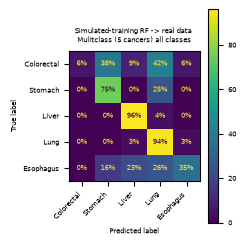

In [14]:
loadMultiRFArchive(
    config=elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G,
)

mcRF300RealMB = getModelBundle(
            config=elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy_G,
            dataSet="real"
            )

bId = "b"
bWidthMM, bHeight = getSubplotWidthAndHeight(plotLayout_G, bId )
mcRF300RealFig = plotArtworkFinalCM( mcRF300RealMB,
                                     widthInMM=bWidthMM, #75,
                                     heightInMM=bHeight, #75,
                                     chenOrdering=['Colorectal_Cancer', 'Stomach_Cancer',
                                                    'Liver_Cancer', 'Lung_Cancer', 
                                                    'Esophagus_Cancer'],
                                    #  title="Simulated-training RF -> Real data \nMulitclass (5 cancers) All classes"
                                     title="Simulated-training RF -> real data \nMulitclass (5 cancers) all classes"
                                    ) 

plotLayout_G[bId].figure = mcRF300RealFig

2026-11-21 10:36:10,159 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/simulatedData/elifeMultiClassifierFrom400Binary.sh.out_best400_results/formatSynthetics.py.out/X.pandas.h5]


data set : elifeMultiClassifierFrom400BinaryDropHealthyLung



2026-11-21 10:36:15,079 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/simulatedData/elifeMultiClassifierFrom400Binary.sh.out_best400_results/formatSynthetics.py.out/y.pandas.h5]
2026-11-21 10:36:18,394 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_all_norm_counts_2023-05-18.csv]
2026-11-21 10:36:19,441 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elife/elife_scaled_metaData_2023-05-18.csv]
2026-11-21 10:36:19,528 WARNING configMLWorkflow.py configTrain() line:345] [loading previously trained model]


'/private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/archive.json' exists .
├── abstract
├── panels
│   └── elifeMultiClassifierFrom400BinaryDropHealthyLung_results'upsetPlot'
├── results
├── runTimeStamp
└── diagnosticBundles

/private/home/aedavids/graceM/src/jupyterNotebooks/multiClassifier.out/elifeMultiClassifierFrom400BinaryDropHealthyLung/multi/archive_multi.json
real.shape : (146, 1525)
layout[c].widthMm : 60
layout[c].heightMm : 65


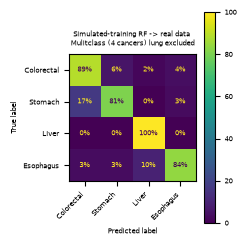

In [15]:
loadMultiRFArchive(
    config=elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G,
)

mcRF400RealMB = getModelBundle(
            config=elifeMultiClassifierFrom400BinaryDropHealthy_Lung_G,
            dataSet="real"
            )
cId = "c"
cWidthInMM, cHeightInMM = getSubplotWidthAndHeight(plotLayout_G, cId)
mcRF400RealFig = plotArtworkFinalCM( mcRF400RealMB,
                                     widthInMM=cWidthInMM, #75,
                                     heightInMM=cHeightInMM, #75,
                                    chenOrdering=['Colorectal_Cancer', 'Stomach_Cancer',
                                                    'Liver_Cancer',  
                                                    'Esophagus_Cancer'],
            # title="Simulated-training RF -> Real data \nMulitclass (4 cancers) Lung excluded"
            title="Simulated-training RF -> real data \nMulitclass (4 cancers) lung excluded"

                                    )

plotLayout_G[cId].figure = mcRF400RealFig

## <span style="color:red;background-color:yellow;">load Deep NN model</span>

In [16]:
p = f'{notebookDir}/deepMultiClassifier.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy'
pp = f'{p}/models/'
! ls $pp
# 2026-10-06.bestLearningRate.1e-05.keras
# 2026-10-06.bestLearningRate.1e-05.keras.preprocessing.joblib
ppp = f'{pp}/2026-10-06.bestLearningRate.1e-05.keras'
!ls $ppp

2026-10-06.bestLearningRate.1e-05.keras
2026-10-06.bestLearningRate.1e-05.keras.preprocessing.joblib
/private/home/aedavids/graceM/src/jupyterNotebooks/deepMultiClassifier.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/models//2026-10-06.bestLearningRate.1e-05.keras


In [ ]:
deepRootDir   = f'{notebookDir}/deepMultiClassifier.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy'
modelPath   = f'{deepRootDir}/models/2026-10-06.bestLearningRate.1e-05.keras'
logger.warning(f'loading model : {modelPath}')
deepModel = keras.models.load_model(
    modelPath,
    compile=False,  # Compilation is unnecessary for prediction.
)

# XDF = mcRF300RealMB.XDF
# # X must have the same feature order and preprocessing as training.
# probabilities = loadedModel.predict(XDF, verbose=0)

# # For a multiclass model with a softmax output:
# predictedCodes = np.argmax(probabilities, axis=1)

mcDeep300RealMB = deepcopy(mcRF300RealMB)
mcDeep300RealMB.model = deepModel
predictionClassOrder = mcDeep300RealMB.y.cat.categories.tolist()

# load the scaler (ie preprocessor)
preprocessingPath = f'{deepRootDir}/models/2026-10-06.bestLearningRate.1e-05.keras.preprocessing.joblib'
logger.warning(f'loading preprocessing : {preprocessingPath}')
preprocessing = joblib.load(preprocessingPath)

mcDeep300RealMB = deepcopy(mcRF300RealMB)
mcDeep300RealMB.model = deepModel

# Select the same features in the same order used during NN training.
XRealDF = mcRF300RealMB.X.loc[:, preprocessing["featureNames"]]

# Apply the original training scaler; preserve sample and feature labels.
mcDeep300RealMB.X = pd.DataFrame(
    preprocessing["scaler"].transform(XRealDF),
    index=XRealDF.index,
    columns=XRealDF.columns,
)


2026-11-21 10:36:21,243 WARNING 2879295985.py <module>() line:5] [loading model : /private/home/aedavids/graceM/src/jupyterNotebooks/deepMultiClassifier.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/models/2026-10-06.bestLearningRate.1e-05.keras]
E0000 00:00:1795286181.270420 1794476 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
2026-11-21 10:36:21,478 WARNING 2879295985.py <module>() line:24] [loading preprocessing : /private/home/aedavids/graceM/src/jupyterNotebooks/deepMultiClassifier.out/elifeMultiClassifierFrom300_1vsAllRelaxedDropHealthy/models/2026-10-06.bestLearningRate.1e-05.keras.preprocessing.joblib]


layout[g].widthMm : 65
layout[g].heightMm : 65


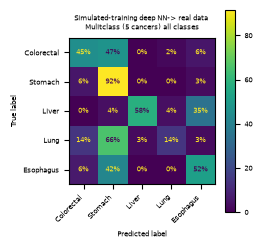

In [18]:
def deep5CancerCM():
    # eId = "e"
    gId = "g"
    eWidthMM, eHeight = getSubplotWidthAndHeight(plotLayout_G, gId)
    mcDeep300RealFig = plotArtworkFinalCM( mcDeep300RealMB,
                                        widthInMM=eWidthMM, #75,
                                        heightInMM=eHeight, #75,
                                        chenOrdering=['Colorectal_Cancer', 'Stomach_Cancer',
                                                        'Liver_Cancer', 'Lung_Cancer', 
                                                        'Esophagus_Cancer'],
                                        #  title="Simulated-training Deep NN-> Real data \nMulitclass (5 cancers) All classes",
                                        title="Simulated-training deep NN-> real data \nMulitclass (5 cancers) all classes",
                                        predictionClassOrder=predictionClassOrder,

                                        ) 
    plotLayout_G[gId].figure = mcDeep300RealFig
    
deep5CancerCM()

## <span style="color:red;background-color:yellow;">10/14/26 daniel suggested adding deep architecture and 4 cancer roc plot </span>

In [19]:
def plotModelArchitecture(
    model,
    widthInMM: float = 90,
    heightInMM: float = 65,
    fontSize: float = 7,
    fontFamily: str = "Ariel",# "DejaVu Sans",
    title: str | None = "Neural network architecture",
) -> tuple[Figure, Axes]:
    """
    Create a compact architecture table for a built Keras model.

    Shows:
        - Layer type
        - Output shape, excluding the batch dimension
        - Activation
        - Number of trainable scalar parameters
        - Total trainable parameters

    Intended for Sequential or Functional models with a linear stack.
    Nested models are displayed as single rows.

    Returns
    -------
    fig, ax
        Matplotlib objects suitable for figure assembly.
        Does not call plt.show() or save the figure.
    """
    if not model.built:
        raise ValueError(
            "The model must be built before plotting its architecture."
        )

    if min(widthInMM, heightInMM, fontSize) <= 0:
        raise ValueError("Dimensions and fontSize must be positive.")

    # Use model-level membership so a frozen parent model is respected.
    trainableIds = {id(weight) for weight in model.trainable_weights}

    def countParameters(weights) -> int:
        # Deduplicate any shared variables.
        uniqueWeights = {id(weight): weight for weight in weights}
        return sum(
            math.prod(int(dimension) for dimension in weight.shape)
            for weight in uniqueWeights.values()
        )

    def formatShape(tensor) -> str:
        if isinstance(tensor, dict):
            return "; ".join(
                f"{key}: {formatShape(value)}"
                for key, value in tensor.items()
            )

        if isinstance(tensor, (list, tuple)):
            return "; ".join(formatShape(item) for item in tensor)

        dimensions = tuple(tensor.shape)[1:]
        return " × ".join(
            "?" if dimension is None else f"{int(dimension):,}"
            for dimension in dimensions
        ) or "Scalar"

    def getOutputShape(layer) -> str:
        try:
            return formatShape(layer.output)
        except (AttributeError, ValueError):
            # Dense layers still expose units if symbolic output is absent.
            if hasattr(layer, "units"):
                return f"{layer.units:,}"
            return "?"

    def getActivation(layer) -> str:
        activation = getattr(layer, "activation", None)

        if activation is not None:
            name = getattr(
                activation, "__name__", activation.__class__.__name__
            )
            return {
                "relu": "ReLU",
                "softmax": "Softmax",
                "sigmoid": "Sigmoid",
                "tanh": "Tanh",
                "linear": "Linear",
                "gelu": "GELU",
                "selu": "SELU",
                "elu": "ELU",
            }.get(name, name)

        # Also recognize standalone activation layers.
        layerType = layer.__class__.__name__
        if layerType in {
            "ReLU", "LeakyReLU", "PReLU", "ELU", "Softmax", "ThresholdedReLU"
        }:
            return layerType

        return "—"

    rows = []
    denseNumber = 0

    for layer in model.layers:
        layerType = layer.__class__.__name__

        # The input dimensionality is already reflected in output shapes.
        if layerType == "InputLayer":
            continue

        if layerType == "Dense":
            denseNumber += 1
            layerLabel = f"Dense {denseNumber}"
        else:
            layerLabel = {
                "GaussianNoise": "Gaussian noise",
                "BatchNormalization": "Batch normalization",
                "LayerNormalization": "Layer normalization",
            }.get(layerType, layerType)

        parameterCount = countParameters(
            weight
            for weight in layer.trainable_weights
            if id(weight) in trainableIds
        )

        rows.append([
            layerLabel,
            getOutputShape(layer),
            getActivation(layer),
            f"{parameterCount:,}",
        ])

    if not rows:
        raise ValueError("No layers available to display.")

    totalParameters = countParameters(model.trainable_weights)
    rows.append(["Total", "", "", f"{totalParameters:,}"])

    fig = plt.figure(
        figsize=(widthInMM / 25.4, heightInMM / 25.4),
        facecolor="white",
    )
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_axis_off()

    if title:
        ax.text(
            0.5, 0.97, title,
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=6, #fontSize,
            fontfamily=fontFamily,
            #fontweight="bold",
        )

    tableBottom = 0.10
    tableTop = 0.85 if title else 0.97

    table = ax.table(
        cellText=rows,
        colLabels=[
            "Layer",
            "Output\nshape",
            "Activation",
            "Trainable\nparameters",
        ],
        colWidths=[0.32, 0.19, 0.20, 0.29],
        cellLoc="left",
        bbox=[0.025, tableBottom, 0.95, tableTop - tableBottom],
    )

    # Preserve the requested font size rather than shrinking automatically.
    table.auto_set_font_size(False)
    table.set_fontsize(fontSize)

    totalRow = len(rows)

    viridis = plt.get_cmap("viridis")

    def tint(color, strength: float):
        """Blend an RGB/RGBA color with white; 0 = white, 1 = original."""
        return tuple(
            (1 - strength) + strength * channel
            for channel in color[:3]
        )

    # purple and sea foam
    # headerColor = viridis(0.05)
    headerColor = tint(viridis(0.05),  strength=0.12)
    denseColor = tint(viridis(0.55), strength=0.10)
    totalColor = tint(viridis(0.05), strength=0.15)
    
    # greenish
    # headerColor = tint(viridis(0.65), strength=0.25)
    # denseColor  = tint(viridis(0.65), strength=0.08)
    # totalColor  = tint(viridis(0.65), strength=0.18)
    # end new color
    
    for (rowIndex, columnIndex), cell in table.get_celld().items():
        cell.set_linewidth(0)
        cell.PAD = 0.06

        text = cell.get_text()
        text.set_fontfamily(fontFamily)
        text.set_fontsize(fontSize)
        text.set_va("center")
        text.set_ha("right" if columnIndex in (1, 3) else "left")

        # text.set_color("black") # new color

        if rowIndex == 0:
            # cell.set_facecolor("#E8EDF0")
            cell.set_facecolor(headerColor)
            text.set_fontweight("bold")

        elif rowIndex == totalRow:
            # cell.set_facecolor("#DDEBE9")
            cell.set_facecolor(totalColor)
            text.set_fontweight("bold")

        elif rows[rowIndex - 1][0].startswith("Dense"):
            # cell.set_facecolor("#F1F6F5")
            cell.set_facecolor(denseColor)

        else:
            cell.set_facecolor("white")

    # Give the two-line header more space than the single-line data rows.
    for (rowIndex, columnIndex), cell in table.get_celld().items():
        cell.set_height(1.7 if rowIndex == 0 else 1.0)
        
    # move this from subplot to the figure's discriptive text
    # ax.text(
    #     0.025, 0.035,
    #     "Output shapes exclude the batch dimension.",
    #     transform=ax.transAxes,
    #     ha="left",
    #     va="bottom",
    #     fontsize=fontSize,
    #     fontfamily=fontFamily,
    #     color="#555555",
    # )

    return fig, ax

2026-11-21 10:36:22,450 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,461 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,462 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,464 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,465 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,466 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,466 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,468 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


layout[f].widthMm : 85
layout[f].heightMm : 47


2026-11-21 10:36:22,647 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,648 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,649 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,650 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,652 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,653 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,654 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:22,656 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


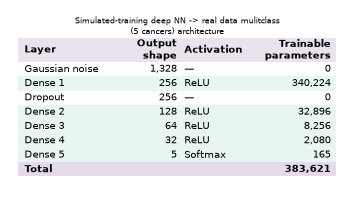

In [20]:
def finalArtworkDeepArch():
    # gId = "g"
    fId = "f"
    # gWidthInMM, gHeightInMM = getSubplotWidthAndHeight(plotLayout_G, gId)
    fWidthInMM, fHeightInMM = getSubplotWidthAndHeight(plotLayout_G, fId)
    architectureFig, architectureAx = plotModelArchitecture(
        model=deepModel,
        widthInMM=fWidthInMM,
        heightInMM=fHeightInMM,
        fontSize=7,
        fontFamily="Arial",
        # title="Simulated-training Deep NN-> Real data \nMulitclass (5 cancers) architecture"
        # title="Simulated-training Deep NN -> Real data Mulitclass\n(5 cancers) architecture"
        title="Simulated-training deep NN -> real data mulitclass\n(5 cancers) architecture"
    )

    plotLayout_G[fId].figure = architectureFig
    
finalArtworkDeepArch()

## <span style="color:red;background-color:yellow;">recreate the roc-auc plot</span>
ref : src/python/models/mlWorkflow.py evaluate()

In [21]:
def plotArtworkFinalRocAUC(
        modelBundle : ModelBundle,
        widthInMM : int,
        heightInMM : int,
        title : str, 
        fontSize : int = 5, #6, #7,
    ) -> tuple[plt.figure, plt.axes, dict[str,float]]:
    ''' 
    TODO
    ref : src/python/plots/plotROCCurve.py plotROCCurve()
    
    arguments :
    
    ref : 
        src/python/models/mlWorkflow.py evaluate()
        src/python/plots/plotConfusionMatrix.py plotConfusionMatrix()
        see https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay

    '''
    XDF = modelBundle.X
    model = modelBundle.model
    
    ySeries = modelBundle.y
    if not isOrderedCategoricalSeries(ySeries):
        errMsg = f'argument ySeries {type(ySeries)} expected pandas series with an ordered categorical dtype'
        logger.error(errMsg)
        raise TypeError(errMsg)
    
    figSize = (widthInMM / 25.4, heightInMM / 25.4)
    fig, ax = plt.subplots(figsize=figSize)
    
    colorCycle = cycle(['aqua', 'darkorange', 'cornflowerblue', 'red', 'green', 'purple'])

    # classLabelStr =  labelEncoder.inverse_transform(model.classes_)
    classLabelStr =  ySeries.cat.categories
    
    nClasses = len( model.classes_ ) 
    
    fpr, tpr, threshold, roc_auc = calculateMultiClass(model, XDF, ySeries)  
    retAUCDict = dict()  
    for i, color in zip(range(nClasses), colorCycle):
        logger.info(f'\n\nfpr[i] : {fpr[i]}')
        logger.info(f'tpr[i] : {tpr[i]}')
        ax.plot(fpr[i], tpr[i], color=color, lw=2,
                label=f'{classLabelStr[i]} (AUC = {roc_auc[i]:0.2f})')
                # label=f'Class {i} (AUC = {roc_auc[i]:0.2f})')
        retAUCDict[ classLabelStr[i] ] = roc_auc[i]
        
        ax.plot([0, 1], [0, 1], 'k--', lw=2)  # diagonal
    
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(title)
    ax.legend(loc="lower right")
    
    # set the font size
    # Class names, axis labels, and title.
    ax.tick_params(axis="both", labelsize=fontSize)
    ax.xaxis.label.set_fontsize(fontSize)
    ax.yaxis.label.set_fontsize(fontSize)
    ax.title.set_fontsize(fontSize)
    
    legend = ax.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            text.set_fontsize(fontSize) 
        legend.get_title().set_fontsize(fontSize)  
        
        # adjust the legend so that it does not overlap
        # with 45 degree line
        ax.legend(
            loc="lower right",
            fontsize=fontSize,
            labelspacing=0.3, #0.2, #0.15,   # Vertical space between entries.
            borderpad=0.25,      # Padding inside the legend box.
            handlelength=1.5,    # Length of each example line.
            handletextpad=0.4,   # Gap between example line and text.
            borderaxespad=0.3,   # Gap between legend and axes boundary.
        )        

    fig.tight_layout(pad=0.5)
    
    return (fig, ax, retAUCDict)

layout[d].widthMm : 85
layout[d].heightMm : 55


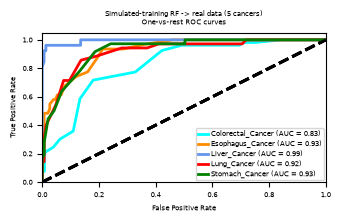

In [22]:
def roc5CancerFinalArt():
    dId = "d" # 5 cancer
    widthMM, height = getSubplotWidthAndHeight(plotLayout_G, dId) 
    t = plotArtworkFinalRocAUC(
        modelBundle=mcRF300RealMB,
        widthInMM=widthMM, #110,
        heightInMM=height, #80,
        # title="simulated-training RF -> Real data (5 cancers)\nOne-vs-rest ROC curves"
        title="Simulated-training RF -> real data (5 cancers)\nOne-vs-rest ROC curves"
    )

    mcRF300RealRocAucFig, mcRF300RealRocAucFigAx, mcRF300RealRocAucDict  = t
    plotLayout_G[dId].figure = mcRF300RealRocAucFig
    
roc5CancerFinalArt()

layout[e].widthMm : 85
layout[e].heightMm : 55


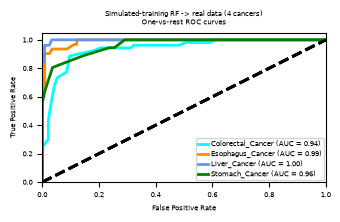

In [23]:
def roc4CancerFinalArtwork() :
    # fId = "f" # 4 cancer
    eId = "e" # 4 cancer
    # gWidthMM, gHeightMM = getSubplotWidthAndHeight(plotLayout_G, fId)
    widthMM, heightMM = getSubplotWidthAndHeight(plotLayout_G, eId)
    t = plotArtworkFinalRocAUC(
        modelBundle=mcRF400RealMB,
        widthInMM=widthMM, #110,#dWidthMM
        heightInMM=heightMM, #80, # dHeight
        # title="simulated-training RF -> Real data (5 cancers)\nOne-vs-rest ROC curves"
        # title="Simulated-training RF -> Real data (4 cancers)\nOne-vs-rest ROC curves"
        title="Simulated-training RF -> real data (4 cancers)\nOne-vs-rest ROC curves"
    )

    mcRF400RealMBRocAucFig, mcRF400RealMBRocAucFigAx, mcRF300RealRocAucDict  = t

    # adjust legend colors so that 4-cancer colors match 5 cancer.
    # in 5 cancer lung = red, stomach = green
    # in unadjust 4 cancer (we dropped lung), stomach is red
    # the easist fix is ot make stomach 4 cancer label green

    def fixStomachROCColor(ax, color="green"):
        # Update the ROC curve.
        for line in ax.get_lines():
            if "stomach" in line.get_label().lower():
                line.set_color(color)

        # Update the existing legend.
        legend = ax.get_legend()
        if legend is not None:
            for text, line in zip(legend.get_texts(), legend.get_lines()):
                if "stomach" in text.get_text().lower():
                    line.set_color(color)
                    
    fixStomachROCColor(mcRF400RealMBRocAucFigAx, color="green" )
    plotLayout_G[eId].figure = mcRF400RealMBRocAucFig
    
roc4CancerFinalArtwork()

## <span style="color:red;background-color:yellow;">create the final artwork figure</span>

Layout valid: 180 × 185 mm total; panels occupy extents of 180 × 185 mm.


2026-11-21 10:36:24,618 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:24,619 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:24,620 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:24,622 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:24,623 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:24,624 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:24,625 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]
2026-11-21 10:36:24,626 WARNING font_manager.py _find_fonts_by_props() line:1606] [findfont: Font family 'Arial' not found.]


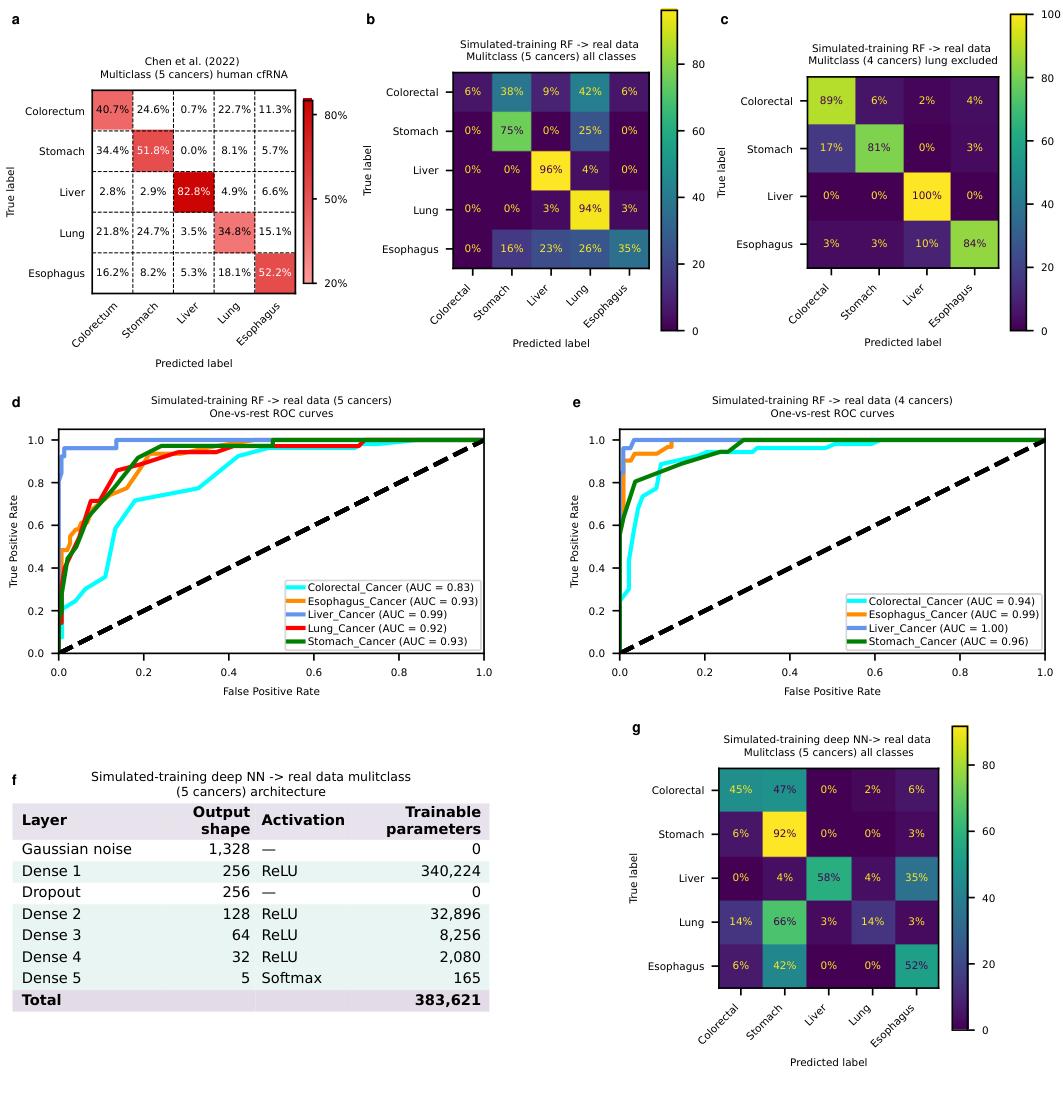

save : /private/home/aedavids/graceM/src/jupyterNotebooks/manuscriptSimulationImprovesPerformance.out/img/panel/manuscript/F_R3_2_SimulatedTrainingPerformance.pdf


In [24]:
F_R3_2OutputStem = Path(f'{imgPanelOutDir}/manuscript/F_R3_2_SimulatedTrainingPerformance')
F_R3_2OutputStem.parent.mkdir(parents=True, exist_ok=True)

# pdfPath, pngPath = combineFiguresLayout(
#     plotLayout_5SubplotsXXX,
#     outputStem=F_R3_2OutputStem,
#     widthMm=180,
#     heightMm=134,
#     legendFigure=None,  # Replace with your legend figure when ready.
#     legendHeightMm=10,
# )

# 10/14/26
pdfPath, pngPath = combineFiguresLayout(
                    panels=plotLayout_G,
                    outputStem=F_R3_2OutputStem,
                    widthMm=180,
                    heightMm=185,
                    addPanelLabels=True,
                    labelFontSize=7,
                    legendFigure=None,
                    legendHeightMm=0,
                    maxWidthMm=180,
                    maxHeightMm=185,
                    pngDpi=600,
)

displayPDFInNotebook(pdfPath)

print(f'save : {pdfPath}')
